# Imports

In [1]:
%pip install tf2onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 10.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from keras.utils import image_dataset_from_directory
from keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.optimizers import Adam
from keras import Model
from keras.models import load_model
import kagglehub
import os
import shutil
import tensorflow as tf
import matplotlib.pyplot as plt
import tf2onnx
import onnx
import datetime

# Dataset dowload

In [3]:
# Dataset 1
path = Path(kagglehub.dataset_download("ahmedmohamedabdallah/breastcancer"))
print("Path to dataset:", path)

Path to dataset: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer


# Analysis and data preprocessment

In [4]:
# Explore data directory
data = Path("/kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data")
print(os.listdir(data))

['Cancer', 'Negative']


In [5]:
classes = list(os.listdir(data))
cancer_data = Path(os.path.join(data, classes[0])) # Bibliography: [Ref.1]
no_cancer_data = Path(os.path.join(data, classes[1])) # Bibliography: [Ref.1]
print(f"Classes: {classes}")
print(f"Cancer images path: {cancer_data}")
print(f"No cancer images path: {no_cancer_data}")

Classes: ['Cancer', 'Negative']
Cancer images path: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data/Cancer
No cancer images path: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data/Negative


In [6]:
# Explore images format
def check_formats(path_data_to_check: Path) -> dict:
    res = {}
    key_res = str(path_data_to_check).split("/")[-1]
    res[key_res] = []
    for image in os.listdir(path_data_to_check):
        _, img_format = image.split(".")
        if img_format not in res[key_res]:
            res[key_res].append(img_format)
    return res

cancer_formats = check_formats(cancer_data)
print(cancer_formats)
no_cancer_formats = check_formats(no_cancer_data)
print(no_cancer_formats)

{'Cancer': ['jpg']}
{'Negative': ['jpg']}


In [7]:
# Check number of images in each class
num_cancer = len(os.listdir(cancer_data))
num_no_cancer = len(os.listdir(no_cancer_data))
print(f"Number of pictures of class 'Cancer : {num_cancer}'")
print(f"Number of pictures of class 'No Cancer : {num_no_cancer}'")

Number of pictures of class 'Cancer : 410'
Number of pictures of class 'No Cancer : 410'


In [8]:
# Prepare data for train, validation, test split
images = []
classes_labels = []

for class_name in os.listdir(data):
    class_path = Path(os.path.join(data, class_name))
    for image in class_path.iterdir():
        images.append(image)
        classes_labels.append(class_name)

# Split data into train, validation and test sets
paths_train, paths_temp, labels_train, labels_temp = train_test_split( # 80% of data for training, 10% for validation and 10% for testing
    images, classes_labels, train_size=0.8  # Bibliography: [Ref.2] and Bibliography: [Ref.3]
)
paths_val, paths_test, labels_val, labels_test = train_test_split(  # Bibliography: [Ref.2] and Bibliography: [Ref.3]
    paths_temp, labels_temp, train_size=0.5
)

print(f"Number of images for training: {len(paths_train)}")
print(f"Number of images for validation: {len(paths_val)}")
print(f"Number of images for testing: {len(paths_test)}")

Number of images for training: 656
Number of images for validation: 82
Number of images for testing: 82


In [9]:
# Create train, validation and test folders and copy the images in there
os.makedirs("train", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("validation", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("test", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("train/Cancer", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("train/Negative", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("validation/Cancer", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("validation/Negative", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("test/Cancer", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("test/Negative", exist_ok=True) # Bibliography: [Ref.4]

def copy_images(images_paths: Path, labels: Path, destination: Path)-> None:
    # Empty folders everytime
    for file in Path(os.path.join(destination, "Cancer")).iterdir():
        file.unlink() # Bibliography: [Ref.5]
    for file in Path(os.path.join(destination, "Negative")).iterdir():
        file.unlink() # Bibliography: [Ref.5]
    # Copy the images
    for image_path, label in zip(images_paths, labels): # Bibliography: [Ref.6]
        if label == "Cancer":
            shutil.copy(image_path, os.path.join(destination, "Cancer")) # Bibliography: [Ref.7]
        elif label == "Negative":
            shutil.copy(image_path, os.path.join(destination, "Negative")) # Bibliography: [Ref.7]

copy_images(paths_train, labels_train, Path("train"))
copy_images(paths_test, labels_test, Path("test"))
copy_images(paths_val, labels_val, Path("validation"))

In [10]:
# Create Tensorflow datasets
train_dir = Path("/kaggle/working/train")
val_dir = Path("/kaggle/working/validation")
test_dir = Path("/kaggle/working/test")

train_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    train_dir,
    labels="inferred",
    color_mode="grayscale",
    batch_size=32,
    image_size=(224, 224)
)
val_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    val_dir,
    labels="inferred",
    color_mode="grayscale",
    batch_size=32,
    image_size=(224, 224)
)
test_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    test_dir,
    labels="inferred",
    color_mode="grayscale",
    batch_size=32,
    image_size=(224, 224)
)

Found 656 files belonging to 2 classes.


I0000 00:00:1793558337.282678      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793558337.286404      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 82 files belonging to 2 classes.
Found 82 files belonging to 2 classes.


# Architecture definition

In [12]:
# Extractor block
input_layer = Input(shape=(224, 224, 1)) # 1 because it's grayscale # Bibliography: [Ref.9]
conv_layer_1 = Conv2D(filters=16, kernel_size=(5, 5), padding="same", activation="relu")(input_layer) # Bibliography: [Ref.10]
max_pooling_layer_1 = MaxPooling2D()(conv_layer_1) # Bibliography: [Ref.11]
conv_layer_2 = Conv2D(filters=32, kernel_size=(3, 3), padding="same", activation="relu")(max_pooling_layer_1) # Bibliography: [Ref.10]
max_pooling_layer_2 = MaxPooling2D()(conv_layer_2) # Bibliography: [Ref.11]
conv_layer_3 = Conv2D(filters=64, kernel_size=(3, 3), padding="same", activation="relu")(max_pooling_layer_2) # Bibliography: [Ref.10]
global_pooling_layer = GlobalAveragePooling2D()(conv_layer_3 )# Bibliography: [Ref.12]
# Classification block
dense_hidden_layer = Dense(1024, activation="relu")(global_pooling_layer) # Bibliography: [Ref.13]
dropout_layer = Dropout(0.5)(dense_hidden_layer) # Bibliography: [Ref.14]
dense_classification_layer = Dense(2, activation="softmax")(dropout_layer) # Bibliography: [Ref.13]

model = Model(inputs=input_layer, outputs=dense_classification_layer) # Bibliography: [Ref.15]

In [13]:
# Model architecture report
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         2,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 92,162 (360.01 KB)

 Trainable params: 92,162 (360.01 KB)

 Non-trainable params: 0 (0.00 B)

# Compilation, training and evaluation

In [14]:
# Model compilation
optimizer = Adam(learning_rate=0.001) # Bibliography: [Ref.16]
model.compile( # Bibliography: [Ref.17]
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy", # Bibliography: [Ref.18]
    metrics=["accuracy"]
)

In [16]:
# Callbacks
early_stopping = EarlyStopping( # Bibliography: [Ref.19]
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
os.makedirs("checkpoints", exist_ok=True) # Bibliography: [Ref.4]
model_checkpoint = ModelCheckpoint( # Bibliography: [Ref.20]
    Path("checkpoints/best.h5"),
    monitor="val_loss",
    save_best_only=True
)

In [18]:
# Training
train_model = model.fit( # Bibliography: [Ref.17]
    train_dataset,
    epochs=300,
    validation_data=val_dataset,
    callbacks=[early_stopping, model_checkpoint]
)

Epoch 1/300


2026-11-01 18:40:03.253128: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-01 18:40:03.393370: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 7/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4882 - loss: 2.5485

I0000 00:00:1793558405.710230     170 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


19/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5130 - loss: 1.8654

2026-11-01 18:40:07.040007: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-01 18:40:07.178907: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (4 outputs left out)

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8643 - loss: 0.3551 - val_accuracy: 0.8780 - val_loss: 0.3549
Epoch 5/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8780 - loss: 0.3327 - val_accuracy: 0.8537 - val_loss: 0.3710
Epoch 6/300
19/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8833 - loss: 0.3448

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8948 - loss: 0.2978 - val_accuracy: 0.9268 - val_loss: 0.3264
Epoch 7/300
19/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9110 - loss: 0.2640

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9055 - loss: 0.2784 - val_accuracy: 0.9390 - val_loss: 0.3041
Epoch 8/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9162 - loss: 0.2493 - val_accuracy: 0.9146 - val_loss: 0.3189
Epoch 9/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9146 - loss: 0.2548 - val_accuracy: 0.9146 - val_loss: 0.3381
Epoch 10/300
19/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9165 - loss: 0.2601

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9223 - loss: 0.2354 - val_accuracy: 0.9390 - val_loss: 0.2808
Epoch 11/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9040 - loss: 0.2619 - val_accuracy: 0.9024 - val_loss: 0.3204
Epoch 12/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9284 - loss: 0.2393 - val_accuracy: 0.9390 - val_loss: 0.2975
Epoch 13/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9009 - loss: 0.2744 - val_accuracy: 0.9268 - val_loss: 0.3442
Epoch 14/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9192 - loss: 0.2372 - val_accuracy: 0.9268 - val_loss: 0.2956
Epoch 15/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9085 - loss: 0.2639 - val_accuracy: 0.9146 - val_loss: 0.3662


In [20]:
# Model evaluation
test_loss, test_accuracy = model.evaluate(test_dataset) # Bibliography: [Ref.21]
print(f"Testing loss: {test_loss}")
print(f"Testing accuracy: {(test_accuracy*100)}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9268 - loss: 0.2092
Testing loss: 0.20924057066440582
Testing accuracy: 92.68292784690857%


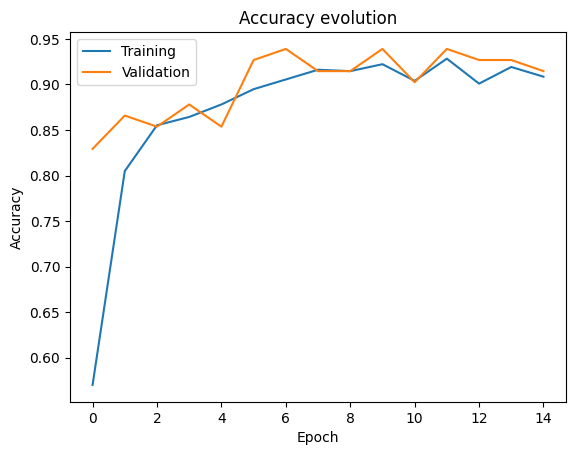

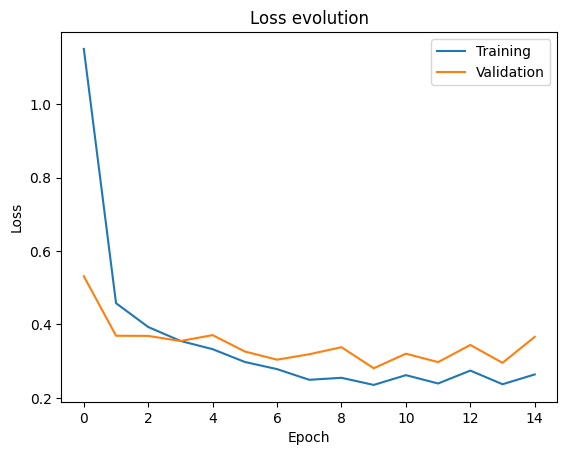

In [25]:
# Model evaluation - Graphics
plt.figure()
plt.plot(train_model.history["accuracy"]) # Bibliography: [Ref.22]
plt.plot(train_model.history["val_accuracy"]) # Bibliography: [Ref.22]
plt.title("Accuracy evolution")
plt.xlabel("Epoch") # Bibliography: [Ref.23]
plt.ylabel("Accuracy") # Bibliography: [Ref.24]
plt.legend(["Training", "Validation"]) # Bibliography: [Ref.25]
plt.show()

plt.figure()
plt.plot(train_model.history["loss"]) # Bibliography: [Ref.22]
plt.plot(train_model.history["val_loss"]) # Bibliography: [Ref.22]
plt.title("Loss evolution")
plt.xlabel("Epoch") # Bibliography: [Ref.23]
plt.ylabel("Loss") # Bibliography: [Ref.24]
plt.legend(["Training", "Validation"]) # Bibliography: [Ref.25]
plt.show()

# Model exportation to onnx

In [24]:
# Conversion from .h5 to onnx -  # Bibliography: [Ref.26]
model_keras = load_model("checkpoints/best.h5")
onnx_model, _ = tf2onnx.convert.from_keras(model_keras)
name_onnx = f"Exp1-{datetime.datetime.now().strftime("%d-%m-%Y")}-CNN.onnx" # Bibliography: [Ref.27]
onnx.save(onnx_model, name_onnx)

I0000 00:00:1793558507.067672      50 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1793558507.067862      50 single_machine.cc:376] Starting new session
I0000 00:00:1793558507.082868      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793558507.084631      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1793558507.144211      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793558507.145865      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 M

# Bibliographic references

<div style="background-color: #c3fac4; border-color: #dfb54; border-left: 5px solid #dfb5b4; padding: 0.5em;">

<strong>Citation style: ISO 690.<strong>

[Ref.1] -- <em>Python|os.path.join() method</em> [online][accessed: 31st October 2026]. Available at: <a href="https://www.geeksforgeeks.org/python/python-os-path-join-method/">https://www.geeksforgeeks.org/python/python-os-path-join-method/</a>

[Ref.2] -- <em>train_test_split</em> [online][accessed: 1st November 2026]. Available at: <a href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html">https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html</a>

[Ref.3] -- <em>Sklearn train_test_split: Dividir datos para Machine Learning en Python</em> [online][accessed: 31st October 2026]. Available at: <a href="https://docs.kanaries.net/es/topics/Scikit-Learn/sklearn-train-test-split">https://docs.kanaries.net/es/topics/Scikit-Learn/sklearn-train-test-split</a>

[Ref.4] -- <em>Python: Create a Directory if it Doesn’t Exist</em> [online][accessed: 1st November 2026]. Available at: <a href="https://datagy.io/python-create-directory-if-doesnt-exist/">https://datagy.io/python-create-directory-if-doesnt-exist/</a>

[Ref.5] -- <em>How to empty an entire directory with Python?</em> [online][accessed: 1st November 2026]. Available at: <a href="https://www.tradingcode.net/python/empty-clear-directory/">https://www.tradingcode.net/python/empty-clear-directory/</a>

[Ref.6] -- <em>Python zip() Function</em> [online][accessed: 1st November 2026]. Available at: <a href="https://www.w3schools.com/python/ref_func_zip.asp">https://www.w3schools.com/python/ref_func_zip.asp</a>

[Ref.7] -- <em>How do I copy a file?</em> [online][accessed: 1st November 2026]. Available at: <a href="https://stackoverflow.com/questions/123198/how-do-i-copy-a-file">https://stackoverflow.com/questions/123198/how-do-i-copy-a-file</a>

[Ref.8] -- <em>Image data loading</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/data_loading/image/">https://keras.io/api/data_loading/image/</a>

[Ref.9] -- <em>Input object</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/core_layers/input/">https://keras.io/api/layers/core_layers/input/</a>

[Ref.10] -- <em>Conv2D layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/convolution_layers/convolution2d/">https://keras.io/api/layers/convolution_layers/convolution2d/</a>

[Ref.11] -- <em>MaxPooling2D layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/pooling_layers/max_pooling2d/">https://keras.io/api/layers/pooling_layers/max_pooling2d/</a>

[Ref.12] -- <em>GlobalAveragePooling2D layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/pooling_layers/global_average_pooling2d/">https://keras.io/api/layers/pooling_layers/global_average_pooling2d/</a>

[Ref.13] -- <em>Dense layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/core_layers/dense/">https://keras.io/api/layers/core_layers/dense/</a>

[Ref.14] -- <em>Dropout layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/regularization_layers/dropout/">https://keras.io/api/layers/regularization_layers/dropout/</a>

[Ref.15] -- <em>The Model class</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/models/model/">https://keras.io/api/models/model/</a>

[Ref.16] -- <em>Adam</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/optimizers/adam/">https://keras.io/api/optimizers/adam/</a>

[Ref.17] -- <em>Model training APIs</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/models/model_training_apis/">https://keras.io/api/models/model_training_apis/</a>

[Ref.18] -- <em>Probabilistic losses</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class">https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class</a>

[Ref.19] -- <em>EarlyStopping</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/callbacks/early_stopping/">https://keras.io/api/callbacks/early_stopping/</a>

[Ref.20] -- <em>ModelCheckpoint</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/callbacks/model_checkpoint/">https://keras.io/api/callbacks/model_checkpoint/</a>

[Ref.21] -- <em>Difference between Keras model.evaluate() and model.predict()?</em> [online][accessed: 1st November 2026]. Available at: <a href="https://www.geeksforgeeks.org/deep-learning/difference-between-keras-modelevaluate-and-modelpredict/">https://www.geeksforgeeks.org/deep-learning/difference-between-keras-modelevaluate-and-modelpredict/</a>

[Ref.22] -- <em>Display Deep Learning Model Training History in Keras</em> [online][accessed: 1st November 2026]. Available at: <a href="https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/">https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/</a>

[Ref.23] -- <em>matplotlib.pyplot.xlabel</em> [online][accessed: 1st November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html</a>

[Ref.24] -- <em>matplotlib.pyplot.ylabel</em> [online][accessed: 1st November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html</a>

[Ref.25] -- <em>matplotlib.pyplot.legend</em> [online][accessed: 1st November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html</a>

[Ref.26] -- <em>Convert trained Keras models (.h5) to ONNX format.</em> [online][accessed: 1st November 2026]. Available at: <a href="https://medium.com/@sergyoubi/convert-trained-keras-models-h5-to-onnx-format-e25819bbf5dd">https://medium.com/@sergyoubi/convert-trained-keras-models-h5-to-onnx-format-e25819bbf5dd</a>

[Ref.27] -- <em>Python Datetime</em> [online][accessed: 1st November 2026]. Available at: <a href="https://www.w3schools.com/python/python_datetime.asp">https://www.w3schools.com/python/python_datetime.asp</a>

[Ref.] -- <em></em> [online][accessed: 1st November 2026]. Available at: <a href=""></a>